# Step 6: Feature engineering

**Project:** Learning What "Normal" Looks Like: Clustering-Based Contextual Anomaly Detection in Bike Sharing

Feature extraction turns raw data into variables that describe what matters for the question (Introduction, Slides 42 to 43). This notebook does three things:

1. **collects** the features already built in Steps 1 to 5, so they are documented in one place;
2. **adds new features** about *when* bad weather happens, weather *relative to the season*, daylight and holidays;
3. **checks which features relate to demand**, separately for casual and registered riders, because that is what the second research question needs.

The features are used in Step 7 to build the calendar baseline and to explain anomalies. They are **not** used in the clustering, which stays based on riding patterns only.

**Inputs:** `hour_clean.csv`, `day_info.csv`, `shape_all.csv`, `level.csv`, `clusters_all.csv`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})

hour = pd.read_csv("hour_clean.csv", parse_dates=["dteday"])
info = pd.read_csv("day_info.csv", index_col="dteday", parse_dates=True)
shape = pd.read_csv("shape_all.csv", index_col="dteday", parse_dates=True)
level = pd.read_csv("level.csv", index_col="dteday", parse_dates=True)
clusters = pd.read_csv("clusters_all.csv", index_col="dteday", parse_dates=True)
features = pd.DataFrame(index=info.index)

## 1. Features built in earlier steps

| Feature | Built in | Why it matters |
| --- | --- | --- |
| Weather in real units (°C, %, km/h) | Step 1 | Readable values; impossible readings become visible |
| Data-quality flags (missing hours, replaced sensor values) | Step 1 | Keeps every correction traceable |
| Daily mean weather, worst weather of the day | Step 2 | One weather summary per day |
| Bad-weather daytime hours (07:00 to 20:00) | Step 2 | Rain at night does not stop riders; rain during the day does |
| Casual share | Step 2 | Separates leisure-driven days from commuting days |
| **Shape** (24 hourly shares, smoothed) | Step 3 | How people ride, independent of growth |
| **Level** (log2 of total relative to similar nearby days) | Step 3 | How much they ride, independent of season and growth |
| PCA scores (commuting vs midday, morning vs evening) | Step 4 | Compact description of the shape |
| Day type and GMM likelihood | Step 5 | The learned context of each day |

The new features below add information that none of these capture.

## 2. New features

### 2a. Time-of-day shares

How much of the day's riding happens in the commuting hours and late in the evening. These are easier to explain to the bike company than PCA scores.

In [2]:
features["rush_share"] = shape[["h07", "h08", "h16", "h17", "h18", "h19"]].sum(axis=1)
features["late_evening_share"] = shape[["h20", "h21", "h22", "h23"]].sum(axis=1)
features[["rush_share", "late_evening_share"]].describe().round(2)

,rush_share,late_evening_share
count,731.00,731.00
mean,0.45,0.13
std,0.11,0.03
min,0.14,0.01
25%,0.33,0.12
50%,0.51,0.13
75%,0.54,0.15
max,0.65,0.31


### 2b. When the bad weather happens

Step 2 counted daytime hours with rain or snow. Here they are split by timing, to test a concrete idea: **rain during commuting hours should hurt registered riders (commuters) more than rain at other times.** Rain on the previous day is added too, because wet roads and forecasts may keep people off bikes the next day.

In [3]:
bad = hour.weathersit == 3
commute = hour.hr.isin([7, 8, 16, 17, 18, 19])
daytime = hour.hr.between(7, 20)

def hours_per_day(mask):
    return hour[mask].groupby("dteday").size().reindex(info.index, fill_value=0)

features["commute_bad_hours"] = hours_per_day(bad & commute)
features["offpeak_bad_hours"] = hours_per_day(bad & daytime & ~commute)
features["bad_hours_yesterday"] = info.bad_weather_daytime_hours.shift(1).fillna(0)
features[["commute_bad_hours", "offpeak_bad_hours", "bad_hours_yesterday"]].describe().round(2)

,commute_bad_hours,offpeak_bad_hours,bad_hours_yesterday
count,731.00,731.00,731.00
mean,0.57,0.66,1.24
std,1.21,1.61,2.59
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.00,0.00,0.00
75%,1.00,0.00,1.00
max,6.00,8.00,14.00


### 2c. Weather relative to the season

People judge weather against what they expect. A 15 °C day feels warm in March and cold in July. Two features capture this:

- **temperature anomaly:** the day's mean temperature minus the average of the 15 days around it;
- **feels-like gap:** feels-like temperature minus actual temperature (negative = wind chill, positive = humid heat).

In [4]:
features["temp_anomaly_c"] = info.temp_c_mean - info.temp_c_mean.rolling(15, center=True, min_periods=7).mean()
features["feels_like_gap_c"] = info.atemp_c_mean - info.temp_c_mean
features[["temp_anomaly_c", "feels_like_gap_c"]].describe().round(2)

,temp_anomaly_c,feels_like_gap_c
count,731.00,731.00
mean,0.01,0.05
std,2.77,2.30
min,-8.55,-7.30
25%,-1.74,-1.50
50%,0.01,0.50
75%,1.76,1.60
max,9.77,8.20


### 2d. Daylight

Hours of daylight change from about 9 to almost 15 over the year in Washington, DC, and decide whether an after-work ride happens in daylight. Daylight is not in the dataset, but it can be calculated exactly from the date and the latitude (38.9° N), using the standard approximation for the sun's declination:

declination = 23.44° x sin(360° x (284 + day of year) / 365)

day length (hours) = (24 / π) x arccos( -tan(latitude) x tan(declination) )

In [5]:
LATITUDE = np.radians(38.9)
day_of_year = info.index.dayofyear.values
declination = np.radians(23.44) * np.sin(2 * np.pi * (284 + day_of_year) / 365)
features["daylight_hours"] = 24 / np.pi * np.arccos(-np.tan(LATITUDE) * np.tan(declination))
print(f"Daylight ranges from {features.daylight_hours.min():.1f} to {features.daylight_hours.max():.1f} hours")

Daylight ranges from 9.3 to 14.7 hours


### 2e. Holiday proximity and bridge days

- **days to nearest holiday:** demand may change around holidays (people travel or take extra days off);
- **bridge day:** a working day squeezed between a holiday and a weekend, such as the Friday after Thanksgiving. Officially a working day, but many people take it off, so the calendar label is likely to be wrong.

In [6]:
holidays = info.index[info.holiday == 1]
features["days_to_holiday"] = [min(abs((d - h).days) for h in holidays) for d in info.index]

after_holiday_friday = (info.holiday.shift(1) == 1) & (info.weekday == 5)
before_holiday_monday = (info.holiday.shift(-1) == 1) & (info.weekday == 1)
features["bridge_day"] = ((info.workingday == 1) & (after_holiday_friday | before_holiday_monday)).astype(int)
print("Bridge days:", info.index[features.bridge_day == 1].strftime("%a %d %b %Y").tolist())

Bridge days: ['Fri 25 Nov 2011', 'Fri 23 Nov 2012', 'Mon 24 Dec 2012']


There are only three bridge days in two years (the two Fridays after Thanksgiving and Christmas Eve 2012), too few for statistics. They are kept as a flag, because in Step 7 they are natural candidates for "working days that do not behave like working days".

### 2f. Temperature bands (discretization)

The calendar baseline in Step 7 needs groups of days. Temperature is continuous, so it is discretized (Introduction, Slide 50). Two options from the lecture:

- **equal width:** bands of the same number of degrees;
- **equal frequency (equal depth):** bands with the same number of days.

Equal frequency is chosen, because equal-width bands would leave very few days in the coldest and hottest bands, and a context group with very few days cannot define what is normal.

In [7]:
BANDS = ["cold", "cool", "mild", "warm"]
features["temp_band"] = pd.qcut(info.temp_c_mean, q=4, labels=BANDS)
equal_width = pd.cut(info.temp_c_mean, bins=4, labels=BANDS)

pd.DataFrame({
    "equal frequency: days": features.temp_band.value_counts().reindex(BANDS),
    "equal width: days": equal_width.value_counts().reindex(BANDS),
    "equal frequency: range (°C)": info.temp_c_mean.groupby(features.temp_band, observed=True)
        .agg(lambda t: f"{t.min():.0f} to {t.max():.0f}").reindex(BANDS),
})

,equal frequency: days,equal width: days,equal frequency: range (°C)
cold,183,73,-5 to 8
cool,183,253,8 to 15
mild,184,231,16 to 23
warm,181,174,23 to 32


## 3. Which features relate to demand, and for which riders?

Each feature is correlated with the **level** of casual and registered riders (Step 3: how much they rode compared with similar nearby days). Working days and days off are analysed separately, because riders behave differently on them and mixing them would hide effects.

The level is used rather than raw totals, so the correlations are not driven by the season or by growth.

In [8]:
numeric = ["rush_share", "late_evening_share", "commute_bad_hours", "offpeak_bad_hours",
           "bad_hours_yesterday", "temp_anomaly_c", "feels_like_gap_c", "daylight_hours", "days_to_holiday"]
work = info.workingday == 1

table = pd.DataFrame({
    ("working days", "casual"): features.loc[work, numeric].corrwith(level.level_casual[work]),
    ("working days", "registered"): features.loc[work, numeric].corrwith(level.level_registered[work]),
    ("days off", "casual"): features.loc[~work, numeric].corrwith(level.level_casual[~work]),
    ("days off", "registered"): features.loc[~work, numeric].corrwith(level.level_registered[~work]),
})
table.round(2).style.background_gradient(cmap="RdBu_r", vmin=-0.7, vmax=0.7).format("{:+.2f}")

**What the table shows.**

- **Bad weather hurts both groups strongly** (correlations around -0.5 to -0.6), whether it falls during commuting hours or not.
- **The commuting-hour hypothesis is not supported.** Rain during commuting hours does not hurt registered riders more than rain at other times of the day: both correlate at about -0.6. A likely reason is that rain rarely stays inside one time window, so commuters who see rain at noon also expect it on the way home. This is a useful negative result: total daytime rain is enough, and timing adds little.
- **Rain the day before** still lowers demand a little on working days (about -0.2), but not on days off.
- **Casual riders respond to unusually warm days much more than registered riders**, especially on days off. This supports the second research question: casual riders react to how pleasant the day is, commuters ride anyway.
- **Rush-hour share** relates to the registered level only: on days when commuters ride a lot, the shape is more peaked.
- **Days to the nearest holiday** has at most a weak effect (below 0.2 everywhere).

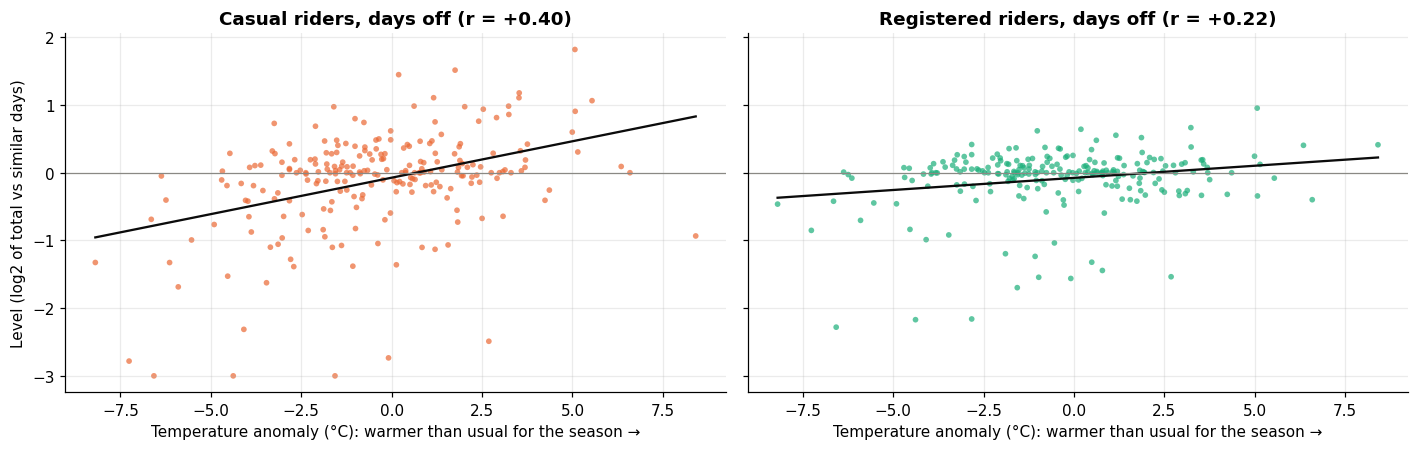

In [9]:
off = ~work
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, g, color in zip(axes, ["casual", "registered"], [ORANGE, AQUA]):
    x = features.temp_anomaly_c[off]
    y = level[f"level_{g}"][off].clip(lower=-3)
    ax.scatter(x, y, s=14, color=color, alpha=0.7, edgecolors="none")
    slope, intercept = np.polyfit(x.dropna(), y[x.notna()], 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, slope * xs + intercept, color="#0b0b0b", linewidth=1.5)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set(title=f"{g.capitalize()} riders, days off (r = {x.corr(level[f'level_{g}'][off]):+.2f})",
           xlabel="Temperature anomaly (°C): warmer than usual for the season →")
axes[0].set_ylabel("Level (log2 of total vs similar days)")
fig.tight_layout()
plt.show()

On a day off that is 5 °C warmer than usual for the season, casual demand rises by roughly half a doubling (about 1.4 times the usual), while registered demand rises by less than a fifth of a doubling. For the bike company, an unexpected warm weekend is a **casual-rider event**: more bikes at leisure locations, and a chance to sell day passes.

Values below -3 are drawn at -3 so the few storm days do not compress the axis; the line is fitted on the same clipped values.

## 4. Daylight and the timing of riding

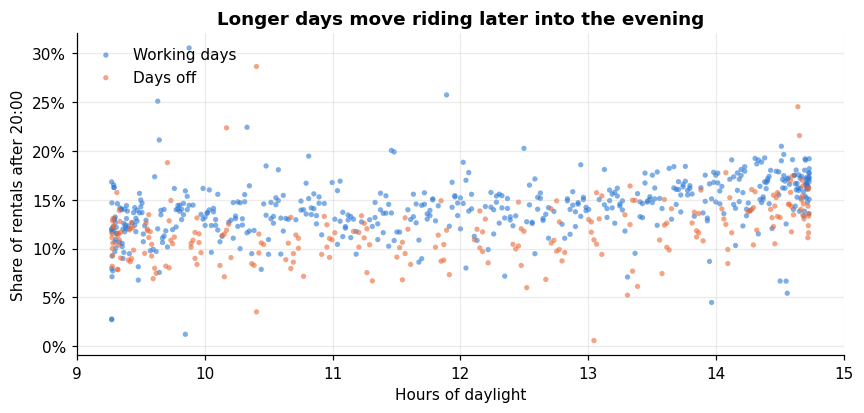

Correlation, all days: +0.38; with casual share: +0.40


In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(features.daylight_hours[work], features.late_evening_share[work], s=12, color=BLUE, alpha=0.6,
           edgecolors="none", label="Working days")
ax.scatter(features.daylight_hours[off], features.late_evening_share[off], s=12, color=ORANGE, alpha=0.6,
           edgecolors="none", label="Days off")
ax.set(title="Longer days move riding later into the evening", xlabel="Hours of daylight",
       ylabel="Share of rentals after 20:00")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(frameon=False, loc="upper left")
plt.show()
print(f"Correlation, all days: {features.daylight_hours.corr(features.late_evening_share):+.2f}; "
      f"with casual share: {features.daylight_hours.corr(info.casual_share):+.2f}")

**Result.** With more daylight, a larger share of riding happens after 20:00, and the casual share rises. Daylight therefore explains part of the seasonal change in day shapes, separately from temperature.

## 5. Save

In [11]:
out = info.join(level.filter(like="level_")).join(features).join(clusters[["day_type"]])
out.to_csv("features_day.csv")
print(f"Saved features_day.csv: {out.shape[0]} days x {out.shape[1]} columns")
print(list(out.columns))

Saved features_day.csv: 731 days x 32 columns
['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'temp_c_mean', 'atemp_c_mean', 'hum_pct_mean', 'wind_kmh_mean', 'weathersit_worst', 'bad_weather_daytime_hours', 'total', 'casual_share', 'missing_hours', 'weather_imputed', 'low_total', 'level_all', 'level_casual', 'level_registered', 'rush_share', 'late_evening_share', 'commute_bad_hours', 'offpeak_bad_hours', 'bad_hours_yesterday', 'temp_anomaly_c', 'feels_like_gap_c', 'daylight_hours', 'days_to_holiday', 'bridge_day', 'temp_band', 'day_type']


## Summary for the report

- Earlier steps already produced the core features: **shape** and **level** per rider group, daily weather summaries, the casual share and the learned **day type**.
- New features: rush-hour and late-evening shares, bad weather split by timing, rain on the previous day, temperature relative to the season, the feels-like gap, **daylight hours** (calculated from date and latitude), holiday proximity, **bridge days** and **temperature bands** (equal-frequency discretization).
- **Findings:**
  - bad weather lowers demand for both rider groups, regardless of when during the day it falls; the hypothesis that commuting-hour rain matters more for registered riders was **not** supported;
  - **casual riders respond strongly to unexpectedly warm days**, registered riders hardly do;
  - more daylight shifts riding into the evening and raises the casual share.
- The temperature bands and weather features are used in Step 7 to build the calendar baseline and to explain detected anomalies.

**Next, Step 7:** anomaly scoring with learned and calendar contexts, the casual versus registered comparison, and evaluation against the verified events list.